In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import math
import random
import time
from pylab import *
from scipy.stats import norm
import seaborn as sns
from scipy.optimize import minimize

#### Defining parameters a,b,c,A


In [2]:
def parameters(sigma,l):
    a = 1/(2 * sigma**2)
    b = 1/(2*l**2)
    c = sqrt(a**2 + 4*a*b)
    A = (1/2)*a + b + (1/2)*c
    return (a,b,c,A)

In [3]:
a,b,c,A = parameters(1,2/5)

#### Recursively implementing the eigenfunctions

In [4]:
def phi(a,c,n,x):
    phi = np.zeros((n,len(x)))
    phi[0,:] = (c/a)**(1/4)*exp((-1/2)*(c-a)*x**2)
    phi[1,:] =  sqrt(2*c)*x*phi[0,:]
    for i in range(2,n):
        phi[i,:] = (sqrt(2*c)*x*phi[i-1,:]/sqrt(i)) - (sqrt(i-1)*phi[i-2,:]/sqrt(i))
    return phi
 

#### Implementing eigenvalues ($\lambda_n$)

In [5]:
def eigen_val(a,b,A,n):
    eig_val = np.zeros(n)
    for i in range(0,n):
        eig_val[i] =np.array([sqrt(a/A) * (b/A)**i]) 
    return eig_val

-------------------------------------------------------------------------------------------------------------------------------------------------------
#### Spectral representation of the GP as a truncated Wiener series ($f_m(x)$) to compute the objective function
------------------------------------------------------------------------------------------------------------------------------------------------------

In [6]:
def f(a,b,c,A,x,w,n):
    n=n+1
    phi_u = phi(a,c,n,x)
    phi_u = np.delete(phi_u, 0, axis=0)
    lambda_u = diag(np.delete(eigen_val(a,b,A,n),0))
    f = phi_u.T @ sqrt(lambda_u) @ w
    return f

#### Plot of the objective function

Text(0.5, 1.0, 'Objective function')

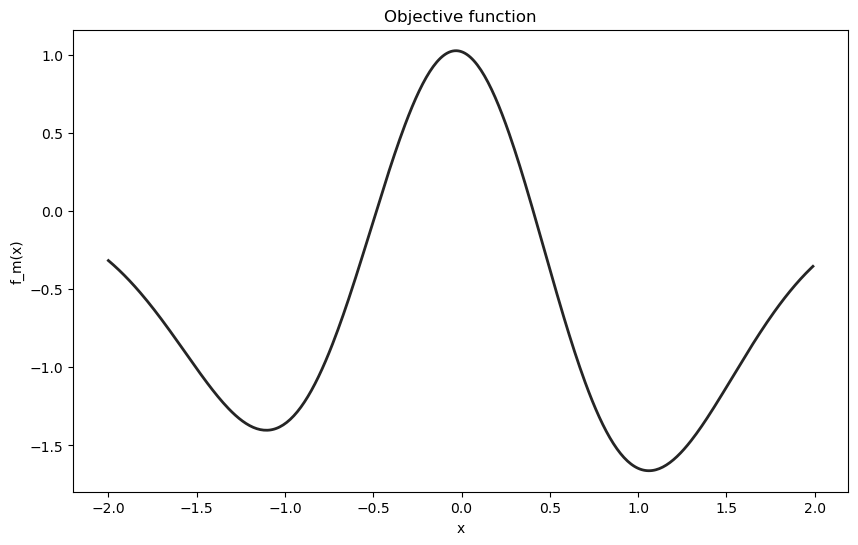

In [7]:
fig = plt.figure(figsize=(10,6))
ax = plt.axes()

#prescribed x_terms
x = np.arange(-2,2,0.01)
w = np.array([-0.25, -2.5])
f_x = f(a,b,c,A,x,w,2)
ax.plot(x, f_x, color='#252525', linewidth=2)
ax.set_xlabel('x')
ax.set_ylabel('f_m(x)')
ax.set_title(f'Objective function')


#### Implementing the observation model

In [8]:
def y_i(a,b,c,X,sigma_n):
    w = np.array([-0.25, -2.5]) 
    z = np.random.normal(0,1,len(X))
    y = f(a,b,c,A,X,w,2) + (sigma_n*z)
    return y

In [9]:
#collecting initial data based on the observation model and given data
X = np.array([-2,0,2])
sigma_n = 10**(-3)
Y = y_i(a,b,c,X,sigma_n)
print(Y)

[-0.31583387  1.02246266 -0.34088316]


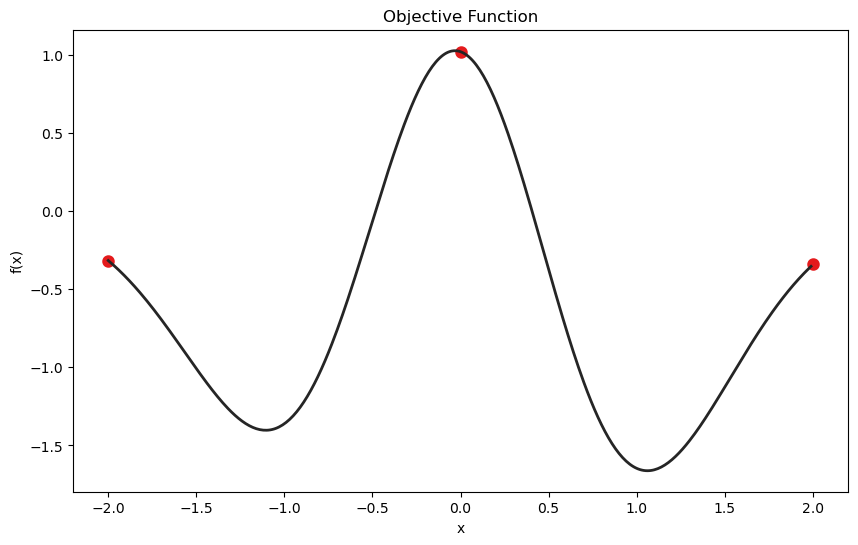

In [10]:
# plot objective function with collected  and given initial data
fig = plt.figure(figsize=(10,6))
ax = plt.axes()
ax.plot(x, f_x, color='#252525', linewidth=2)
ax.set_xlabel('x')
ax.set_ylabel('f(x)')
ax.set_title('Objective Function')

# plot initial data
ax.scatter(X, Y, color='#e41a1c', linewidth=3)

### Bayesian optimization

#### Spectral representation of the GP as a truncated Wiener series to compute surrogate. 

In [11]:
def f_m(a,b,c,A,x,w,n):
    phi_u = phi(a,c,n,x)
    lambda_u = diag(eigen_val(a,b,A,n))
    f = phi_u.T @ sqrt(lambda_u) @ w
    return f 

#### Implementing the GP Posterior 

In [12]:
def w_post(a,b,c,m,sigma_n,X,Y):
    phi_post = phi(a,c,m,X)
    lambda_u = diag(eigen_val(a,b,A,m))
    
    H = phi_post.T @ sqrt(lambda_u)
    U, D, V_t = np.linalg.svd(H, full_matrices=False)
    D_1 = diag (D/(D**2 + sigma_n **2))
    post_mean = V_t.T @ D_1 @ (U.T@Y)
    D_2 = diag (1-sqrt(sigma_n**2/ (D**2 + sigma_n **2)))

    z = np.random.normal(0,1,50)
    Rz = z - (V_t.T @ D_2 @ (V_t@z))
    w_post = post_mean + Rz

    return w_post

#### Computing the Thompson sampling acquisition function

In [13]:
def AF(x,w_post):
    funct = lambda x,w_post : f_m(a,b,c,A,x,w_post,50)
    return funct

In [14]:
def diff_phi(a,b,c,n,x):
    l = len(x)
    x = np.array(x)
    phi_diff = np.zeros((l,n))
    if n==0:
        phi_diff[:,0] = -(c-a) * x * phi(a,c,n,x).T[:,0]
    if n==1:
        phi_diff[:,0] = -(c-a) * x * phi(a,c,n,x).T[:,0]
        phi_diff[:,1] = sqrt(2*c) * (phi(a,c,n,x).T[:,0] + x * phi_diff[:,0])
    if n>1:
        phi_diff[:,0] = -(c-a) * x * phi(a,c,n,x).T[:,0]
        phi_diff[:,1] = sqrt(2*c) * (phi(a,c,n,x).T[:,0] + x * phi_diff[:,0])
        for i in range(2,n):
            j = i-1
            phi_diff[:,i] = sqrt(2*c/i) * (phi(a,c,n,x).T[:,i-1] + x 
                            * phi_diff[:,i-1]) - sqrt((i-1)/i)*phi_diff[:,i-2]
    return phi_diff

In [15]:
def diff_f_m(a, b, c, A, x, w, n):
    diff_phi_u = diff_phi(a,b,c,n,x)
    lambda_u = diag(eigen_val(a,b,A,n))
    diff_f = diff_phi_u @ sqrt(lambda_u) @ w
    return diff_f

In [16]:
def diff_f_posterior(x, w_post):
    return diff_f_m(a, b, c, A, x, w_post, 50)

In [17]:
def Diff_TS_AF(w_post):
    diff_func_x = lambda x, posterior_w: diff_f_posterior(x, w_post)
    return diff_func_x

#### Implementing the BO policy

In [18]:
def BO_policy(a, b, c, m, sigma_n, X, Y, x0):
    # Computing the posterior D_k-1
    post_w = w_post(a,b,c,m,sigma_n,X,Y)
    # derive acquisition function using TS 
    alpha_x = AF(x,post_w)
    diff_alpha_x = Diff_TS_AF(post_w) 
    # minimizing acquisition function
    x0 = np.array(x0)
    len_x0 = x0.size
    min_pts = np.zeros(len_x0)
    f_ret = np.array([f_m(a,b,c,A,np.array([i]),post_w,50) for i in x0])
    f_ret_min = np.min(f_ret)
    sorter = np.argsort(np.array(x0))
    x_min_index = sorter[np.searchsorted(x0, np.array([f_ret_min]), 
                                         sorter=sorter)]
    x_min = x0[x_min_index]
    for i in range(len_x0):
        # using gradient-based algorithm (bounded Broyden–Fletcher–Goldfarb–Shanno (BFGS))
        ret = minimize(alpha_x, [x0[i]], args=(post_w), method='L-BFGS-B', jac = diff_alpha_x, bounds=[(-2,2)])
        f_ret = f_m(a,b,c,A,ret.x,post_w,50)
        if f_ret < f_ret_min:
            f_ret_min = f_ret
            x_min = ret.x
        
    return (x_min,post_w)

#### Iterating 30 times to compute global maximum.

C:\Users\naajenif\AppData\Local\Temp\ipykernel_27196\1795708981.py:18: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=(10,6))


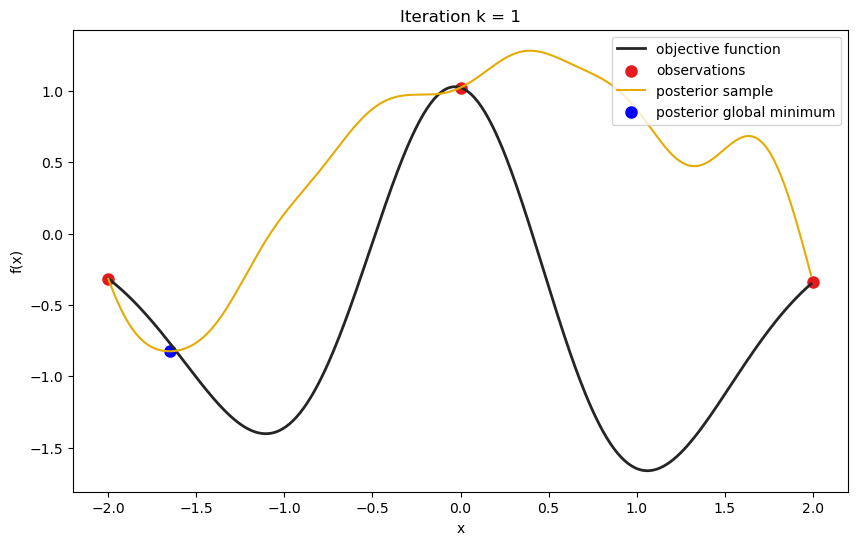

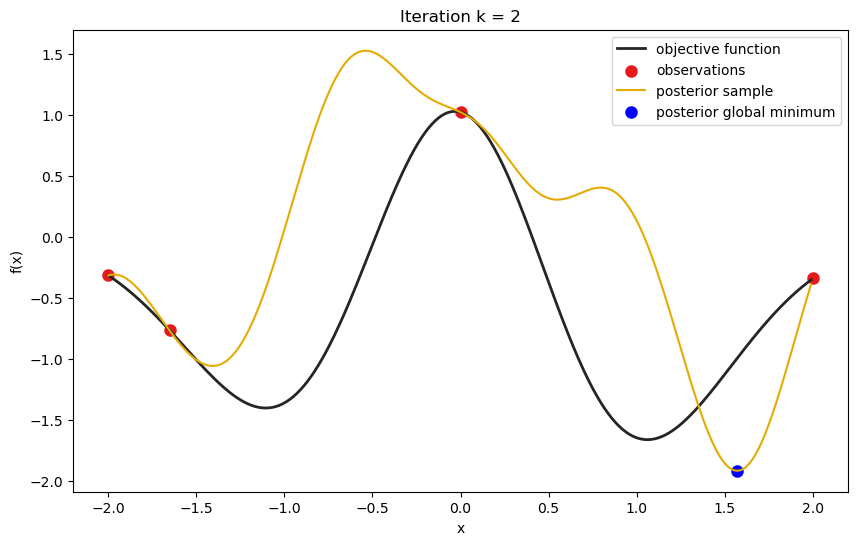

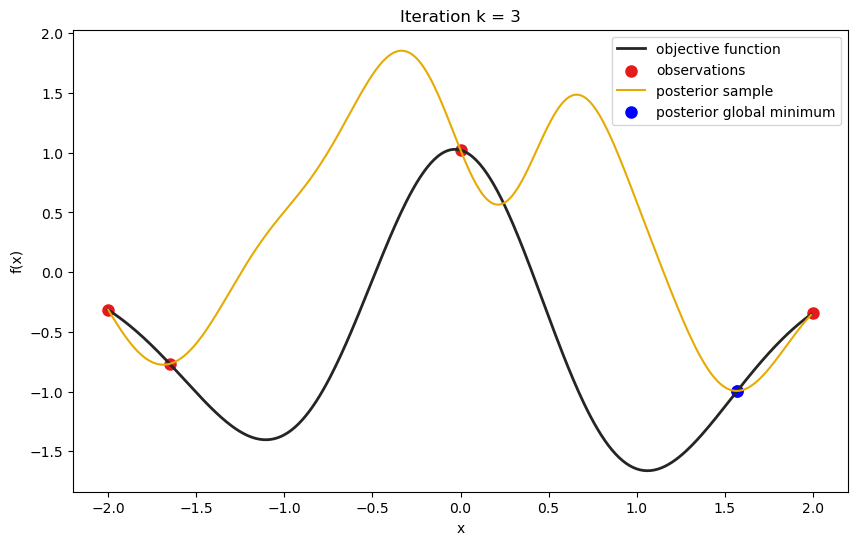

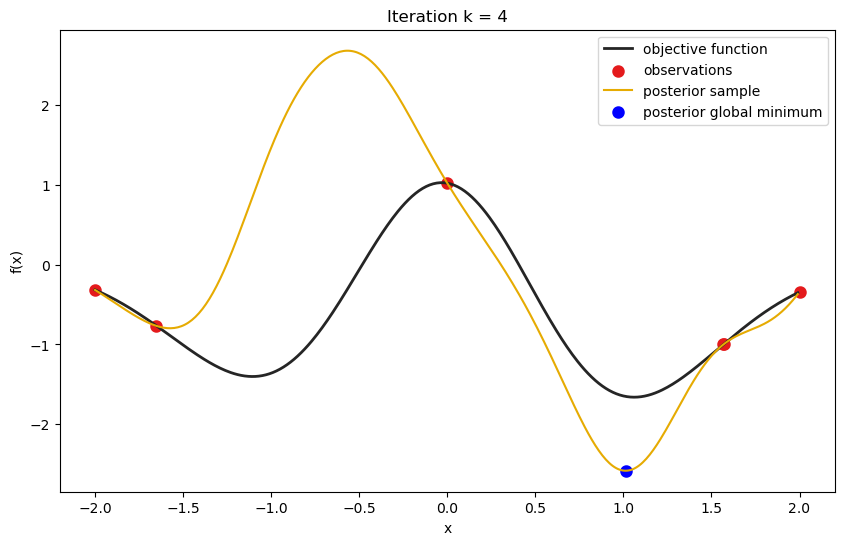

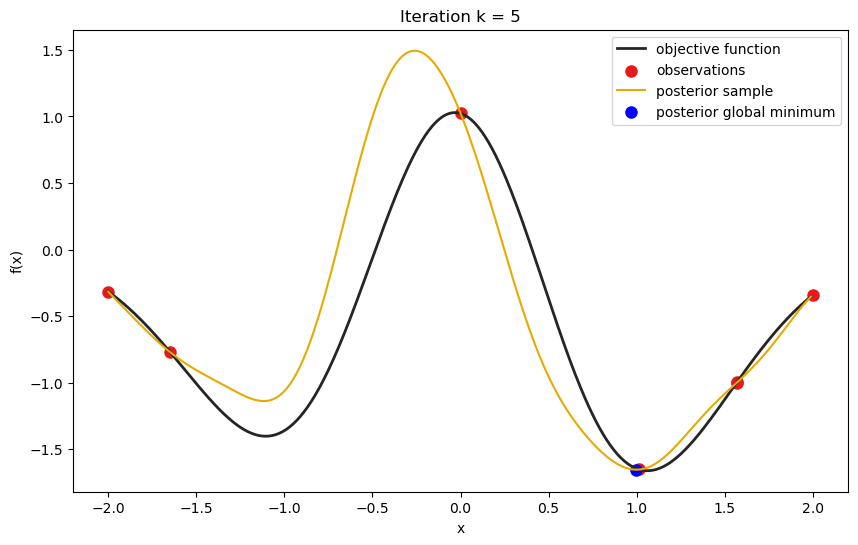

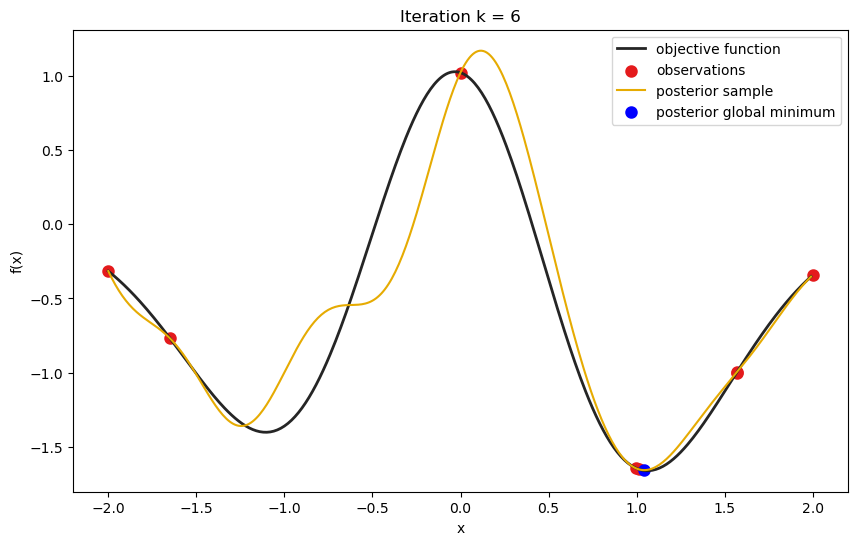

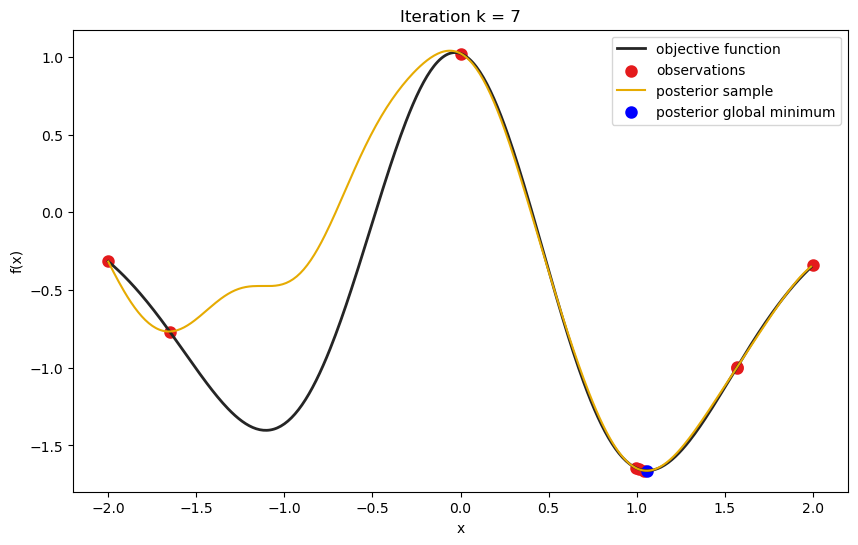

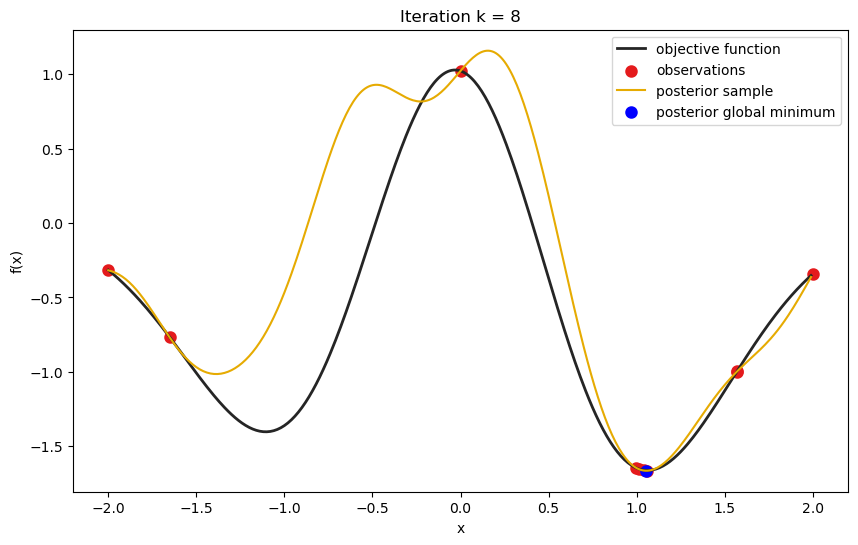

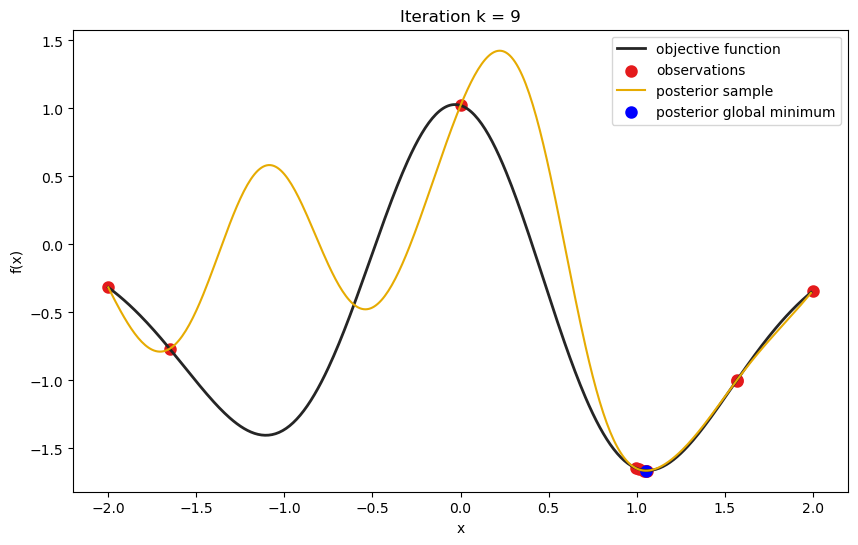

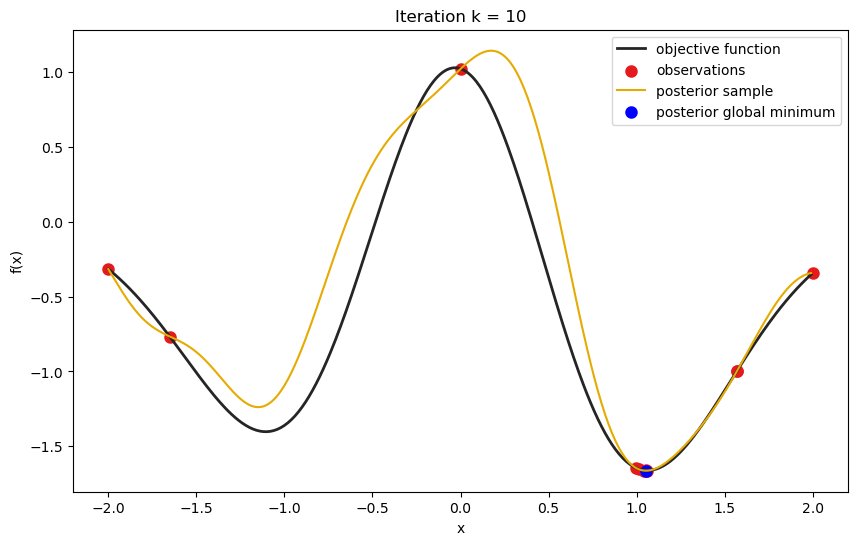

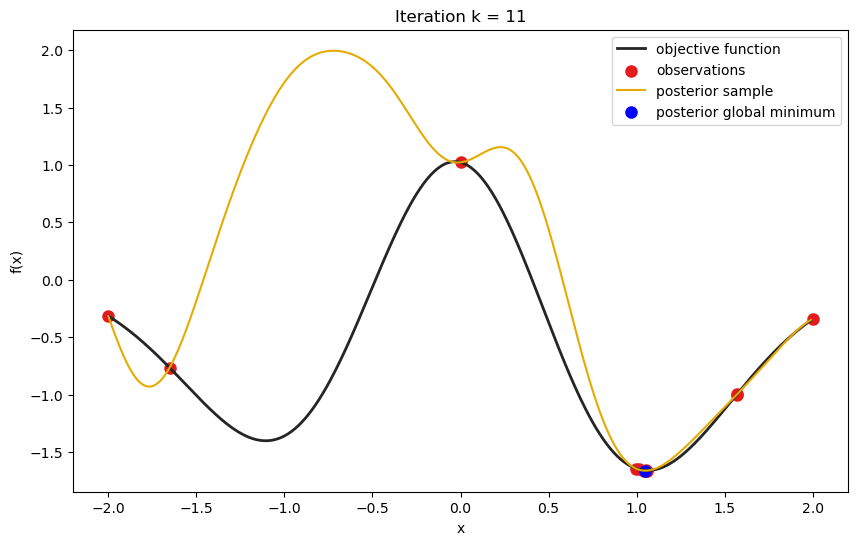

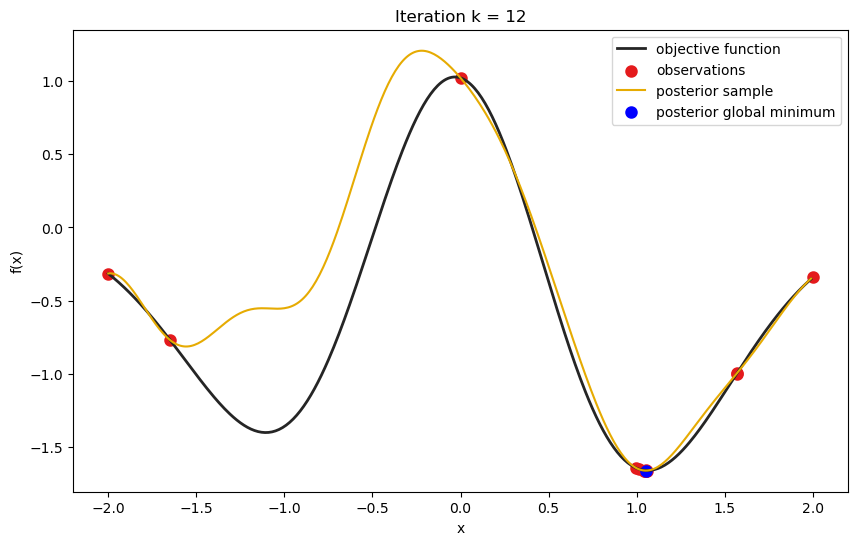

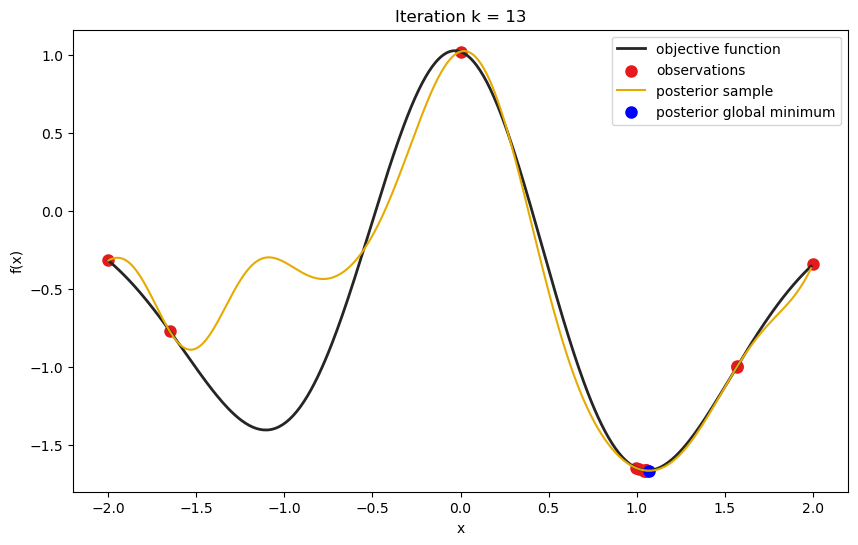

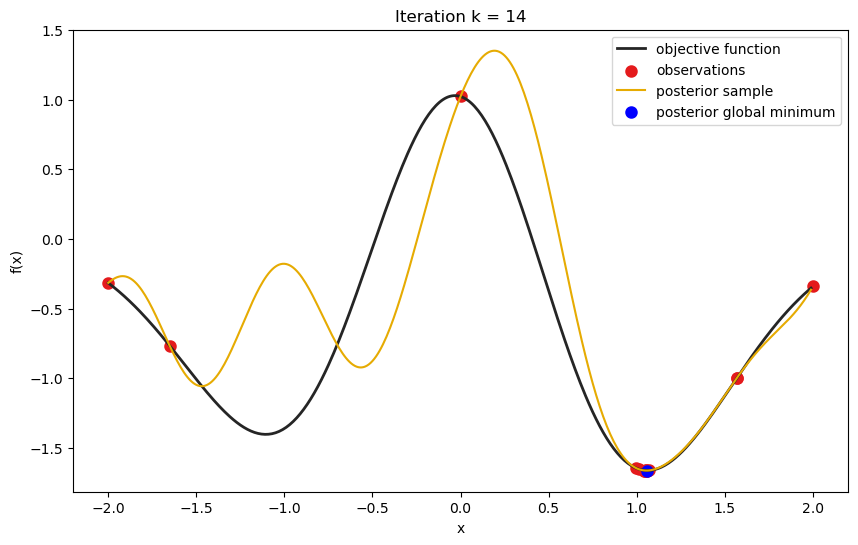

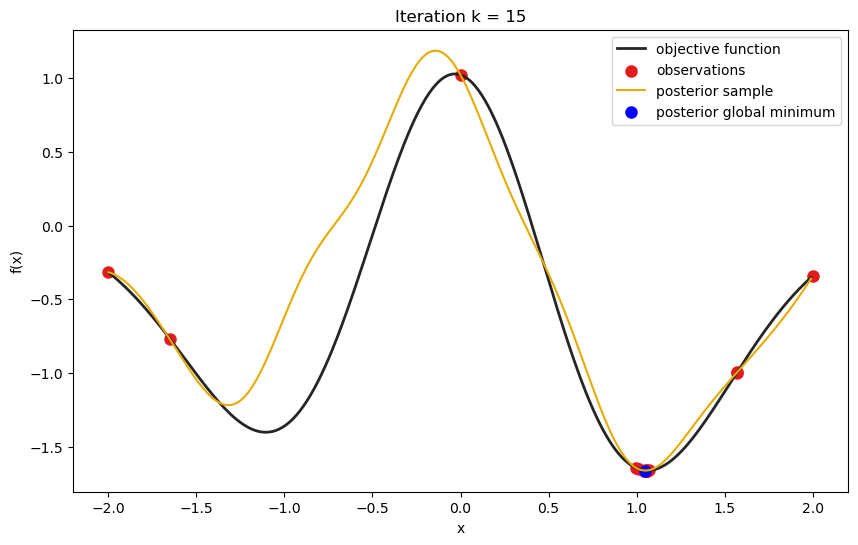

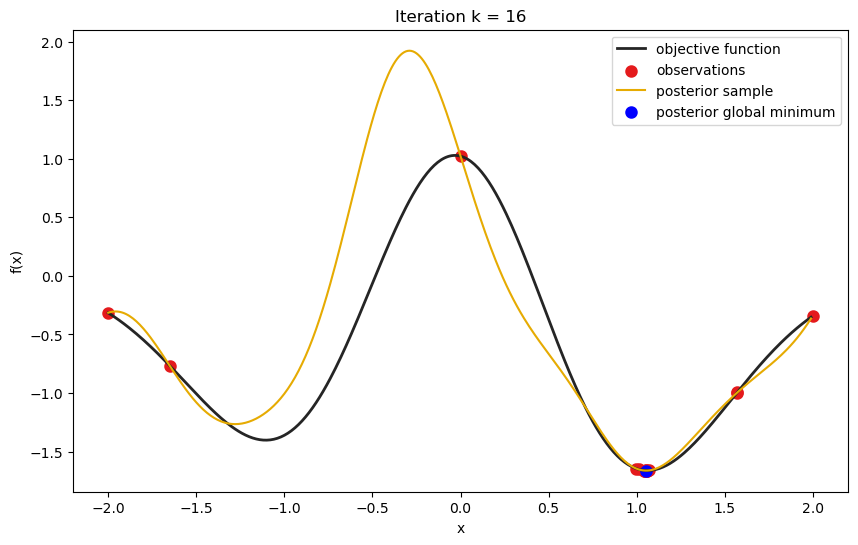

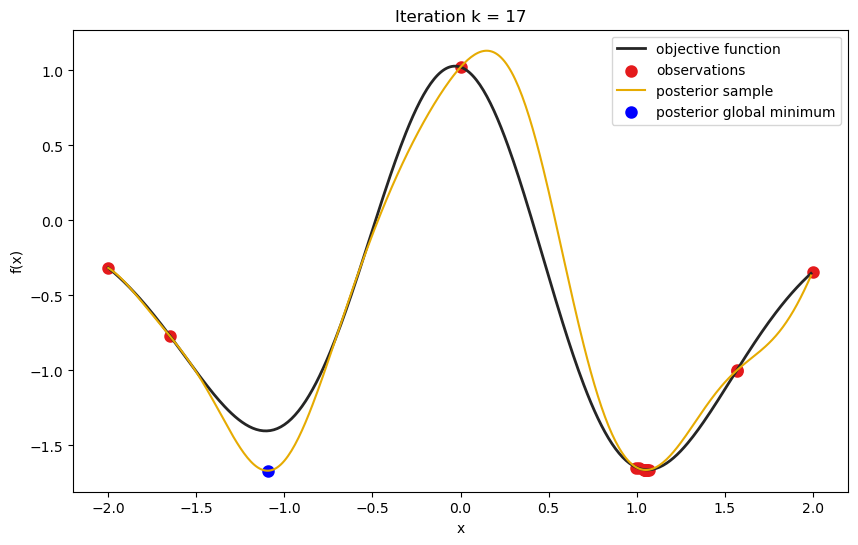

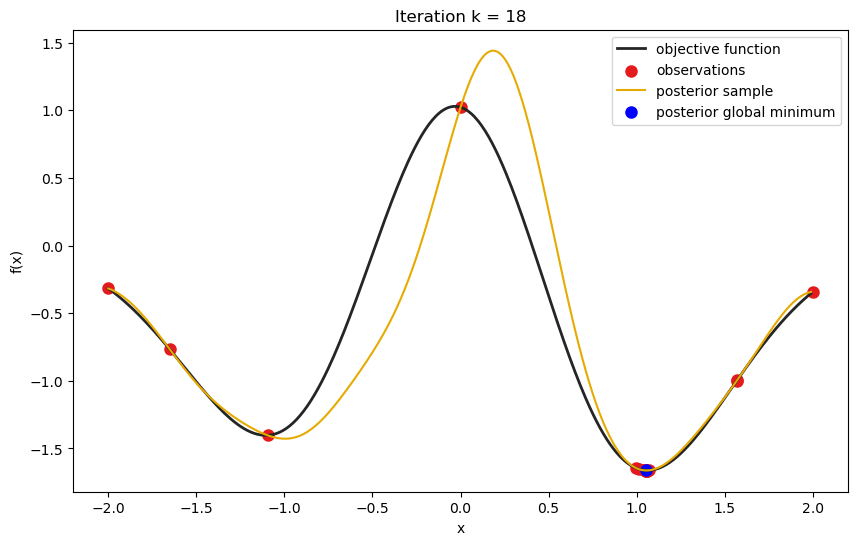

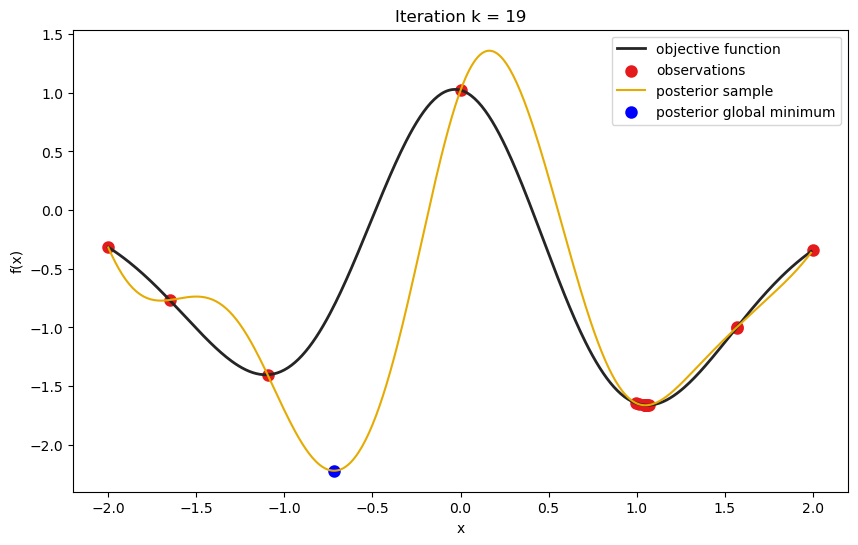

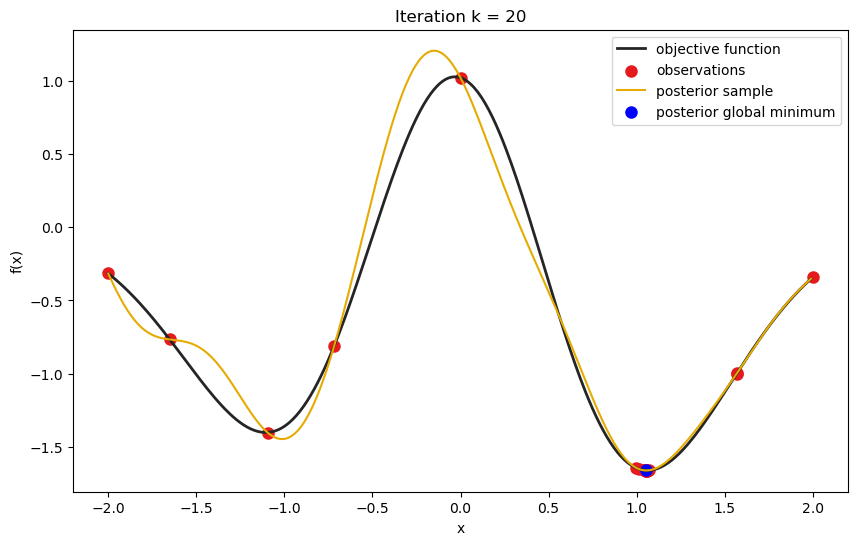

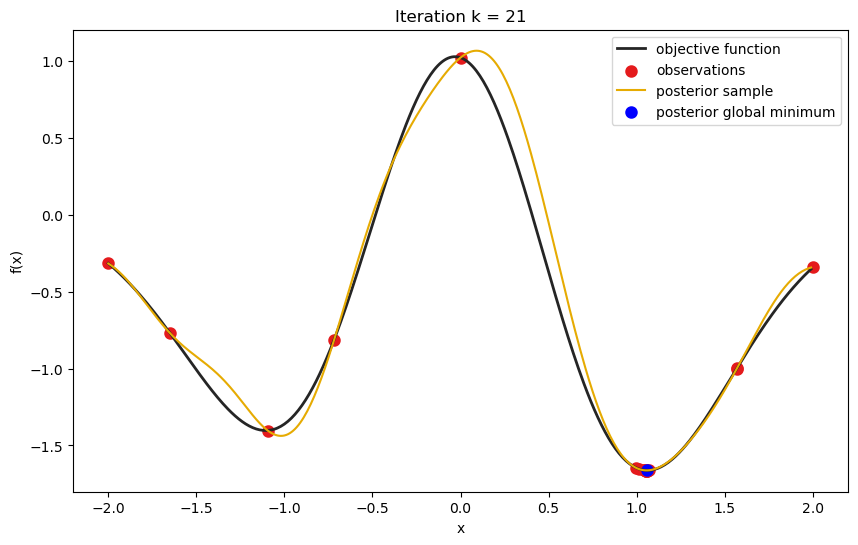

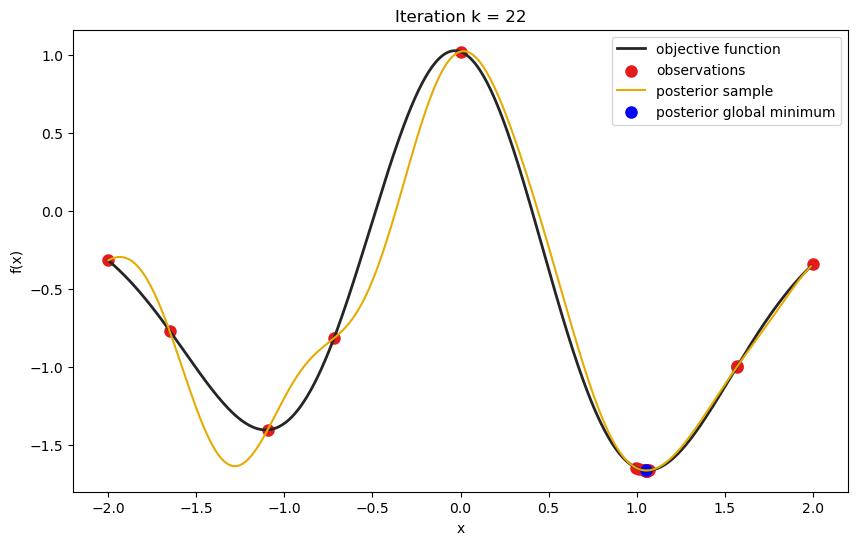

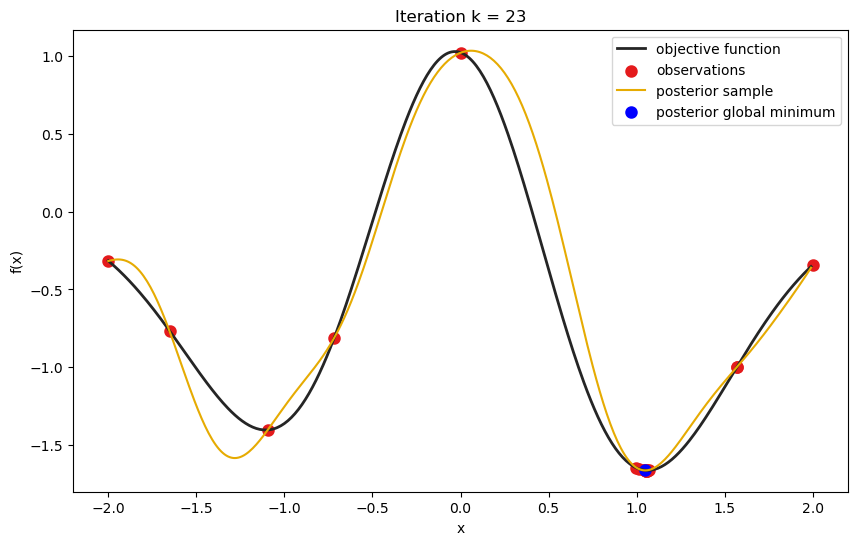

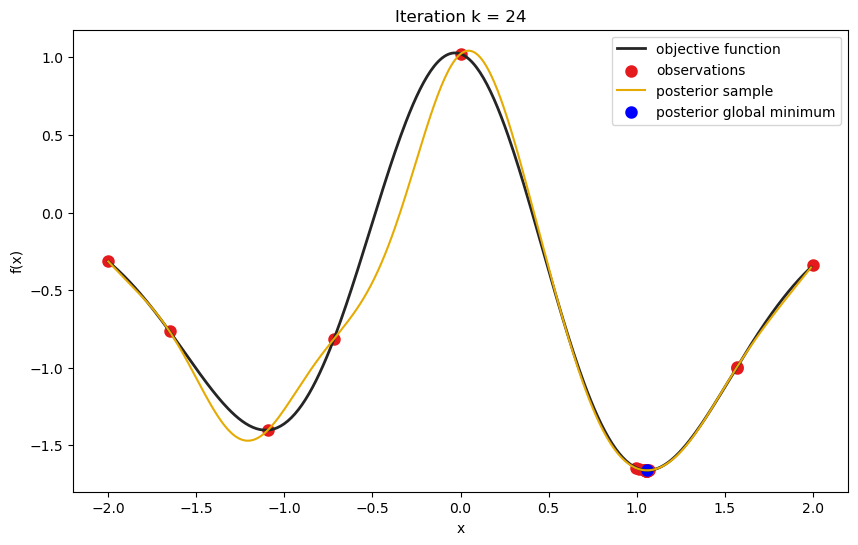

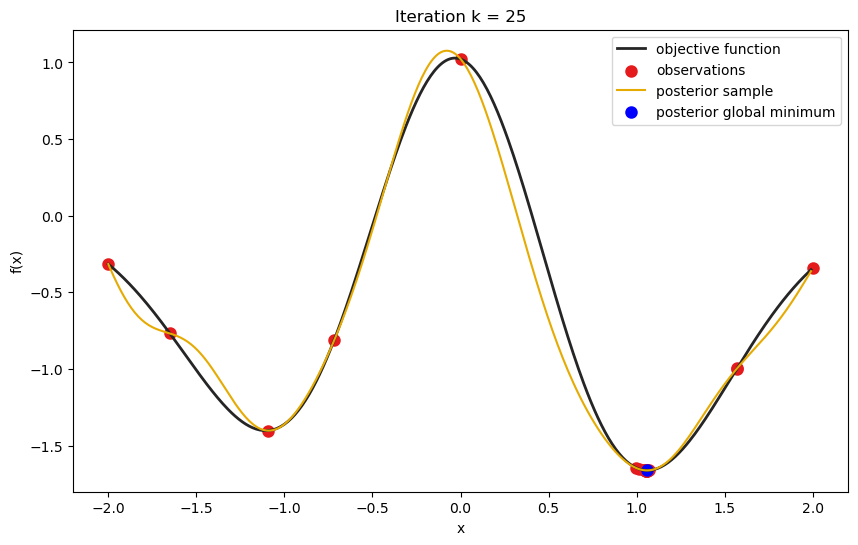

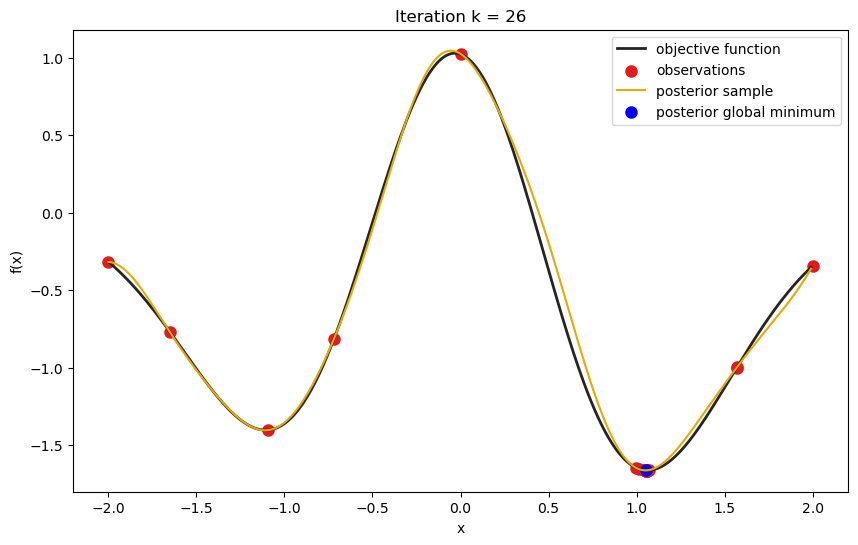

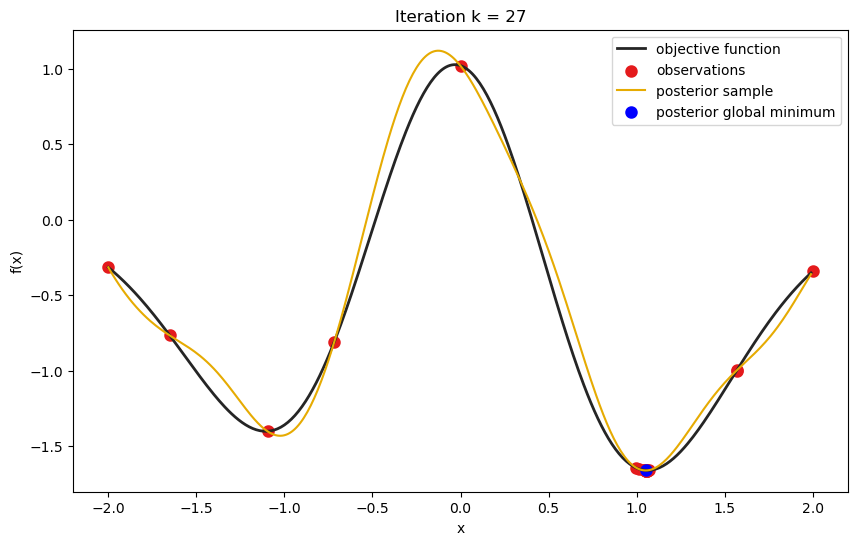

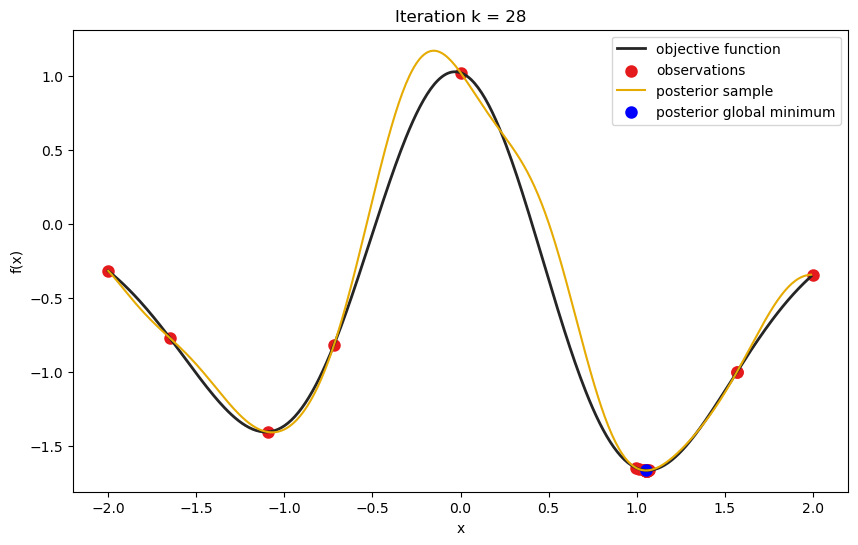

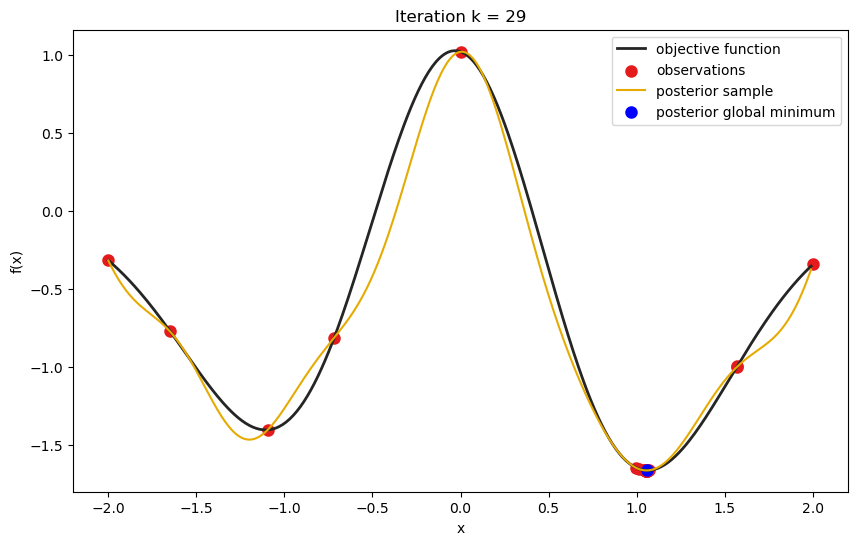

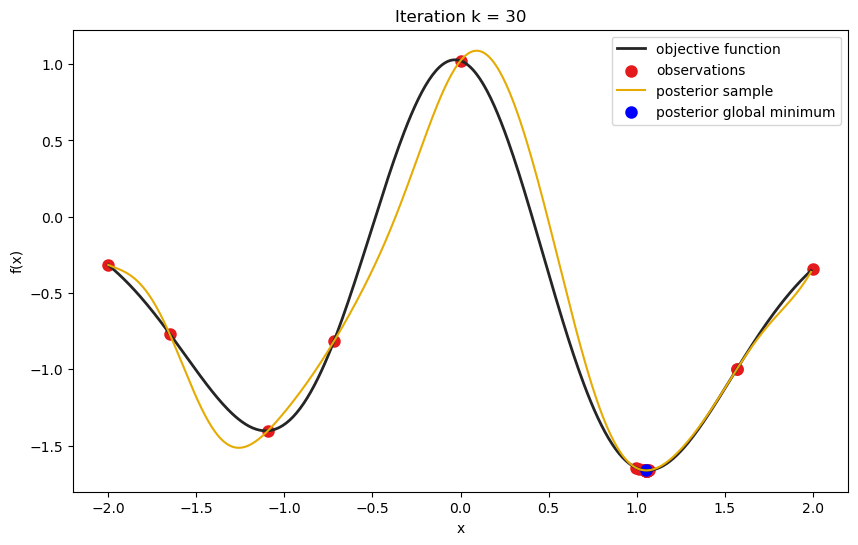

In [19]:
# no of terms
m = 50 
# noise
sigma_n = 10**(-3) 
k = 30 
#inputing initial dataset
X = X
Y = Y
#Implementing sequential optimizataion till the the termination condition is reached
for i in range(30):
    #policy
    x_new, post_w = BO_policy(a, b, c, m, sigma_n, X, Y, [-2,-1,0,1,2])
    x_new = np.array(x_new)
    # observe x_k
    y_new = y_i(a, b, c, x_new, sigma_n) 
    # compute posterior D_k-1
    f_post_new = f_m(a, b, c, A, x_new, post_w, 50)
    fig = plt.figure(figsize=(10,6))
    ax = plt.axes()
    
    # plot objective function
    ax.plot(x, f_x, color='#252525', linewidth=2, label='objective function' )
    
    # plot data
    ax.scatter(X, Y, color='#e41a1c', linewidth=3, label='observations')
    
    # plot posterior
    post_f = f_m(a, b, c, A, x, post_w, 50)
    ax.plot(x, post_f, color = '#e6ab02', linewidth=1.5, label='posterior sample')
    
    # plot new point
    ax.scatter(x_new, f_post_new, color='blue', linewidth=3, label = 'posterior global minimum')
    #ax.scatter(x_new, y_new, color='#e41a1c', linewidth=3)
    ax.set_xlabel('x')
    ax.set_ylabel('f(x)')
    ax.set_title(f'Iteration k = {i+1}')
    ax.legend(loc="upper right")
    # save plot in pdf
    plt.savefig(f'BO_K{i+1}.pdf', bbox_inches="tight")
    
    X = np.append(X, x_new)
    Y = np.append(Y, y_new)